In [25]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
import py_files.config as cfg
import inspect
import os
from py_files.plot_scrip import create_and_save_table
from py_files.functions import (
                       get_tau_array,
                       get_covariation_matrix,
                       get_channel_matrix,
                       get_barlet_values,
                       get_sin_signal,
                       get_impulse_signal, get_noise, 
                       calculate_noise_level, 
                       calculate_energy,
                       get_avp_signals, 
                       get_direction_matrix, 
                       get_est_phi,
                       get_cap_values,
                       calculate_freq_spectr, calculate_99,
                       calculate_f_rms, spectrum_filtering, calculate_time_signa)

config_parametrs = cfg.init_rng()
path = "images/notebook"
os.makedirs(path,exist_ok=True)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [26]:
#sin_signal = get_sin_signal(config_parametrs)
pulse_signal = get_impulse_signal(config_parametrs)
energy_pulse_value = calculate_energy(pulse_signal, config_parametrs["time_vector"])


In [27]:
sin_signal = get_sin_signal(config_parametrs)

pulse_signal = get_impulse_signal(config_parametrs)
pulse_signal_copy = pulse_signal.copy()
energy_pulse_value = calculate_energy(pulse_signal_copy, config_parametrs["time_vector"])

spectrum_signal = calculate_freq_spectr(pulse_signal_copy, cfg.FS)
f_rms_betta = calculate_f_rms(spectrum_signal, config_parametrs)

K = 0.5
B = K*f_rms_betta
width_rms = K*f_rms_betta
spectrum_filtering_signal = spectrum_filtering(spectrum_signal, B)

back_signal = calculate_time_signa(spectrum_filtering_signal)
energy_filt_pulse_value = calculate_energy(back_signal, config_parametrs["time_vector"])
f_rms_new = calculate_f_rms(calculate_freq_spectr(back_signal, cfg.FS),config_parametrs)



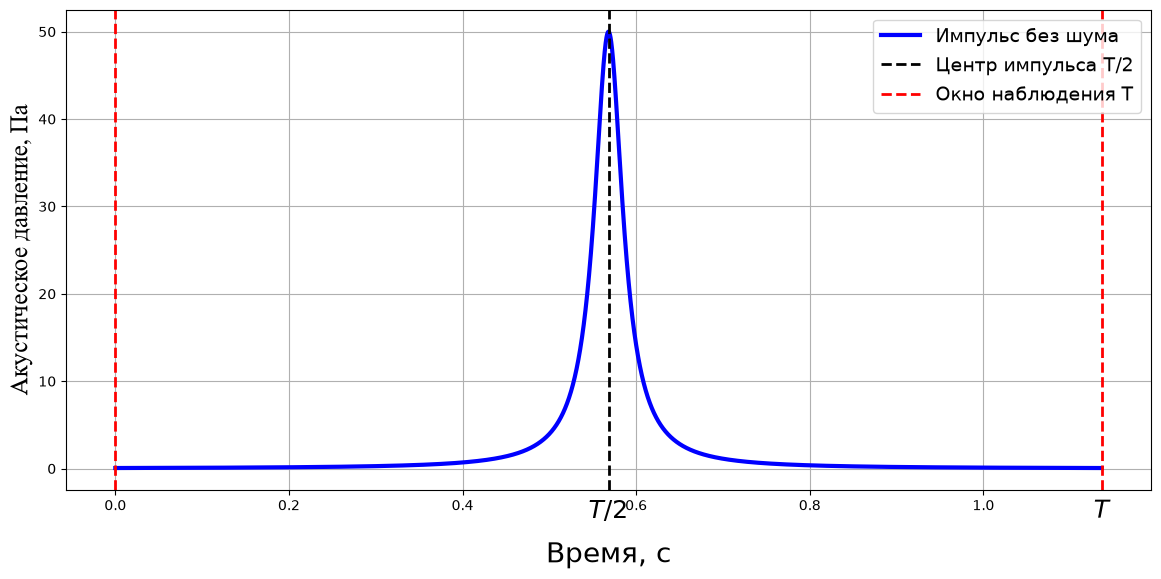

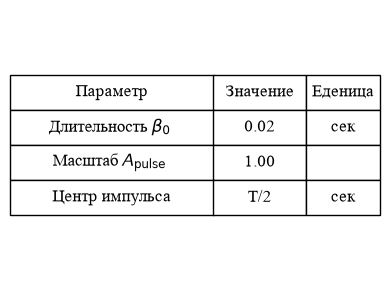

In [28]:


# Построение графика
title_main = "Импульсный сигнал s(t)"
fig, ax = plt.subplots(1, 1, figsize=(14, 8))
fig.subplots_adjust(top=0.85, bottom=0.25)


ax.plot(
    cfg.TIME_VECTOR, pulse_signal,
    color="blue", linewidth=3, label="Импульс без шума"
)

# Названия осей и заголовок
ax.set_xlabel("Время, с", labelpad=20, fontsize=20)
ax.set_ylabel("Акустическое давление, Па", fontsize=18, fontfamily="Times New Roman")


# Центр импульса и отметки времени
ax.axvline(
    config_parametrs["center_pulse"],
    color="black", linestyle="--", linewidth=2,
    label="Центр импульса T/2"
)
ax.axvline(
    0,
    color="red", linestyle="--", linewidth=2,
)
ax.axvline(
    config_parametrs["duration_all"],
    color="red", linestyle="--", linewidth=2,
    label="Окно наблюдения T"
)
ax.text(
    config_parametrs["center_pulse"], -0.02, r"$T/2$",
    transform=ax.get_xaxis_transform(),
    ha="center", va="top", fontsize=18
)
ax.text(
    config_parametrs["duration_all"], -0.02, r"$T$",
    transform=ax.get_xaxis_transform(),
    ha="center", va="top", fontsize=18
)

ax.grid(True)
ax.legend(loc="upper right", fontsize=14)

# Параметры под графиком
plt.savefig(fname = f"images/notebook/{title_main}", bbox_inches = 'tight', dpi = 300)
plt.show()

rows = [
    [r"Длительность $\beta_{\mathrm{0}}$ ", f"{cfg.BETTA_PULSE:.2f}", "сек"],
    [r"Масштаб $A_{\mathrm{pulse}}$ ", f"{cfg.A:.2f}", " "],
    [r"Центр импульса", f"T/2", "сек"]]
create_and_save_table(rows, ["Параметр", "Значение", "Еденица"], f"images/notebook/table_{title_main}")

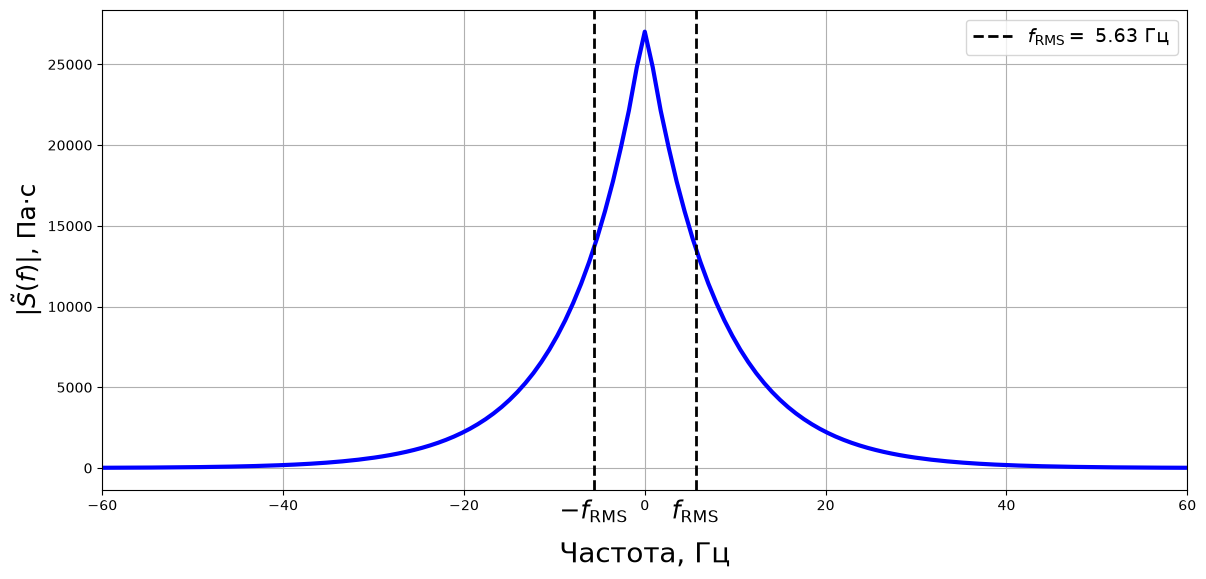

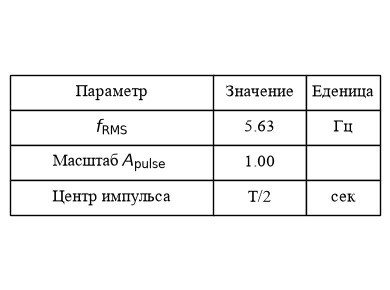

In [29]:


# Построение графика
title_main = "Амплитудный спектр S(f)"
fig, ax = plt.subplots(1, 1, figsize=(14, 8))
fig.subplots_adjust(top=0.85, bottom=0.25)


ax.plot(
    cfg.FREQ_VECTOR, np.abs(spectrum_signal),
    color="blue", linewidth=3
)

# Названия осей и заголовок
ax.set_xlabel("Частота, Гц", labelpad=20, fontsize=20)
ax.set_ylabel(r"$|\tilde{S}(f)|$, Па·с", fontsize=18)

# Центр импульса и отметки времени


ax.axvline(
    -f_rms_betta,
    color="black", linestyle="--", linewidth=2,
)

ax.axvline(
    f_rms_betta,
    color="black", linestyle="--", linewidth=2,
    label=r"$f_\text{RMS} = $" + f" {f_rms_betta:.2f} Гц"
)

ax.legend(loc="upper right", fontsize=14)
ax.text(
    f_rms_betta, -0.02, r"$f_\text{RMS}$",
    transform=ax.get_xaxis_transform(),
    ha="center", va="top", fontsize=18
)
ax.text(
    -f_rms_betta, -0.02, r"$-f_\text{RMS}$",
    transform=ax.get_xaxis_transform(),
    ha="center", va="top", fontsize=18
)
# Параметры под графиком

ax.set_xlim(-60,60)

ax.grid(True)
plt.savefig(fname = f"images/notebook/{title_main}", bbox_inches = 'tight', dpi = 300)
plt.show()

rows = [
    [r"$f_{\mathrm{RMS}}$",
 f"{f_rms_betta:.2f}", "Гц"],
    [r"Масштаб $A_{\mathrm{pulse}}$ ", f"{cfg.A:.2f}", " "],
    [r"Центр импульса", f"T/2", "сек"]]
create_and_save_table(rows, ["Параметр", "Значение", "Еденица"], f"images/notebook/table_{title_main}")

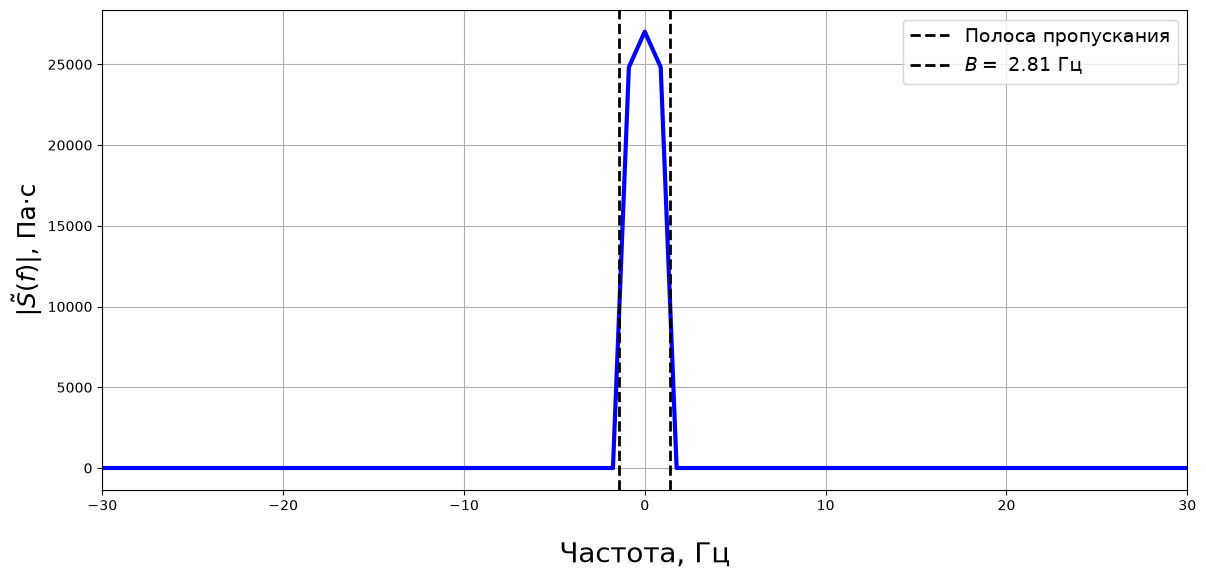

In [30]:


# Построение графика
title_main = "Отфилтрованный амплитудный спектр S(f)"
fig, ax = plt.subplots(1, 1, figsize=(14, 8))
fig.subplots_adjust(top=0.85, bottom=0.25)


ax.plot(
    cfg.FREQ_VECTOR, np.abs(spectrum_filtering_signal),
    color="blue", linewidth=3
)

# Названия осей и заголовок
ax.set_xlabel("Частота, Гц", labelpad=20, fontsize=20)
ax.set_ylabel(r"$|\tilde{S}(f)|$, Па·с", fontsize=18)

# Центр импульса и отметки времени


ax.axvline(
    -B/2,
    color="black", linestyle="--", linewidth=2,
    label="Полоса пропускания"
)

ax.axvline(
    B/2,
    color="black", linestyle="--", linewidth=2,
    label=r"$B  = $" + f" {B:.2f} Гц"
)

ax.legend(loc="upper right", fontsize=14)

# Параметры под графиком

ax.set_xlim(-30,30)

ax.grid(True)
plt.savefig(fname = f"images/notebook/{title_main}", bbox_inches = 'tight', dpi = 300)
plt.show()

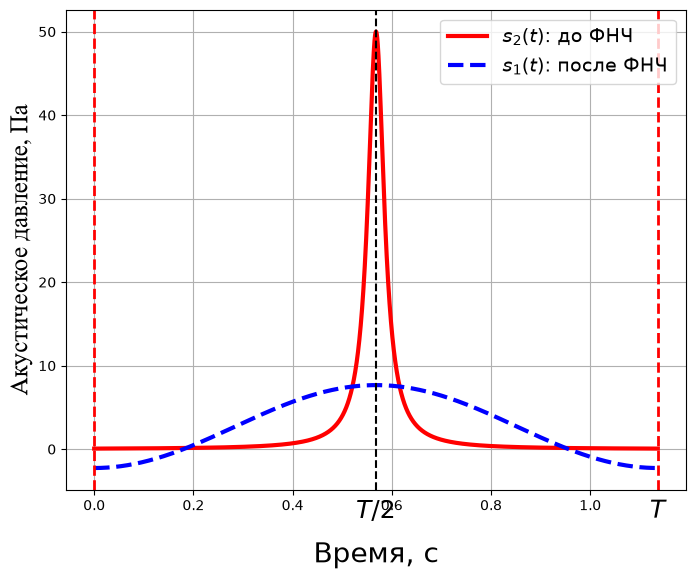

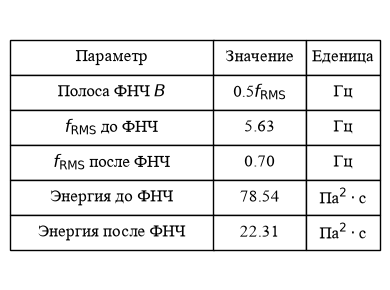

In [31]:


# Построение графика
title_main = "Импульсный сигнал P(t) после фильтрации"
fig, ax = plt.subplots(1, 1, figsize=(8, 8))
fig.subplots_adjust(top=0.85, bottom=0.25)

ax.plot(
    cfg.TIME_VECTOR, pulse_signal_copy,
    color="red", linewidth=3, label=r"$s_\text{2}(t)$: до ФНЧ"
)

ax.plot(
    cfg.TIME_VECTOR, back_signal,
    color="blue", linewidth=3, linestyle="--", label=r"$s_\text{1}(t)$: после ФНЧ"
)


# Названия осей и заголовок
ax.set_xlabel("Время, с", labelpad=20, fontsize=20)
ax.set_ylabel("Акустическое давление, Па", fontsize=18, fontfamily="Times New Roman")


# Центр импульса и отметки времени
ax.axvline(
    config_parametrs["center_pulse"],
    color="black", linestyle="--", linewidth=1.5,
)
ax.axvline(
    0,
    color="red", linestyle="--", linewidth=2,
)
ax.axvline(
    config_parametrs["duration_all"],
    color="red", linestyle="--", linewidth=2
)
ax.text(
    config_parametrs["center_pulse"], -0.02, r"$T/2$",
    transform=ax.get_xaxis_transform(),
    ha="center", va="top", fontsize=18
)
ax.text(
    config_parametrs["duration_all"], -0.02, r"$T$",
    transform=ax.get_xaxis_transform(),
    ha="center", va="top", fontsize=18
)

ax.grid(True)
ax.legend(loc="upper right", fontsize=14)

# Параметры под графиком

plt.savefig(fname = f"images/notebook/{title_main}", bbox_inches = 'tight', dpi = 300)
plt.show()

rows = [
    [r"Полоса ФНЧ $B$", f"{K}"+r"$f_{\mathrm{RMS}}$", "Гц"],
    [r"$f_{\mathrm{RMS}}$ до ФНЧ", f"{f_rms_betta:.2f}", "Гц"],
    [r"$f_{\mathrm{RMS}}$ после ФНЧ", f"{f_rms_new:.2f}", "Гц"],
    ["Энергия до ФНЧ", f"{energy_pulse_value:.2f}", r"Па$^2 \cdot$с"],
    ["Энергия после ФНЧ", f"{energy_filt_pulse_value:.2f}", r"Па$^2 \cdot$с"],
]
create_and_save_table(rows, ["Параметр", "Значение", "Еденица"], f"images/notebook/table_{title_main}")


In [32]:
# Построение графика

title_main = "Зашумлённый импульсный сигнал P(t)"

noise = get_noise(config_parametrs, np.random.default_rng(42), en_signal)
noise_level = calculate_noise_level(en_signal, config_parametrs["snr"], config_parametrs["duration_all"])

noise_signal = pulse_signal_copy + noise
fig, ax = plt.subplots(1, 1, figsize=(14, 10))
fig.subplots_adjust(top=0.85, bottom=0.25)

ax.plot(cfg.TIME_VECTOR, noise_signal, label="Импульс с шумом")
ax.plot(
    cfg.TIME_VECTOR, pulse_signal_copy,
    color="red", linewidth=3, label="Импульс без шума"
)

# Названия осей и заголовок
ax.set_xlabel("Время, с", labelpad=20, fontsize=20)
ax.set_ylabel("Акустическое давление, Па", fontsize=18, fontfamily="Times New Roman")

fig.suptitle(
    title_main,
    y=0.925, va="center",
    fontfamily="Times New Roman", fontsize=22
)

# Центр импульса и отметки времени
ax.axvline(
    config_parametrs["center_pulse"],
    color="black", linestyle="--", linewidth=2,
    label="Центр импульса T/2"
)

ax.text(
    config_parametrs["center_pulse"], -0.02, r"$T/2$",
    transform=ax.get_xaxis_transform(),
    ha="center", va="top", fontsize=18
)
ax.text(
    config_parametrs["duration_all"], -0.02, r"$T$",
    transform=ax.get_xaxis_transform(),
    ha="center", va="top", fontsize=18
)

ax.grid(True)
ax.legend(loc="upper right", fontsize=18)

# Параметры под графиком
info = (
    f"SNR = {cfg.SNR}\n"
    f"СКО шума: {noise_level:.2f}\n"
    f"Интервал наблюдения T: {config_parametrs['duration_all']:.2f} сек."
    
)

ax.text(
    0.5, -0.18, info,
    transform=ax.transAxes,
    fontsize=14, linespacing=1.5,
    ha="center", va="top",
    bbox=dict(boxstyle="round", facecolor="wheat", alpha=1),
    clip_on=False
)
plt.savefig(fname = f"images/notebook/{title_main}", bbox_inches = 'tight', dpi = 300)
plt.show()

NameError: name 'en_signal' is not defined

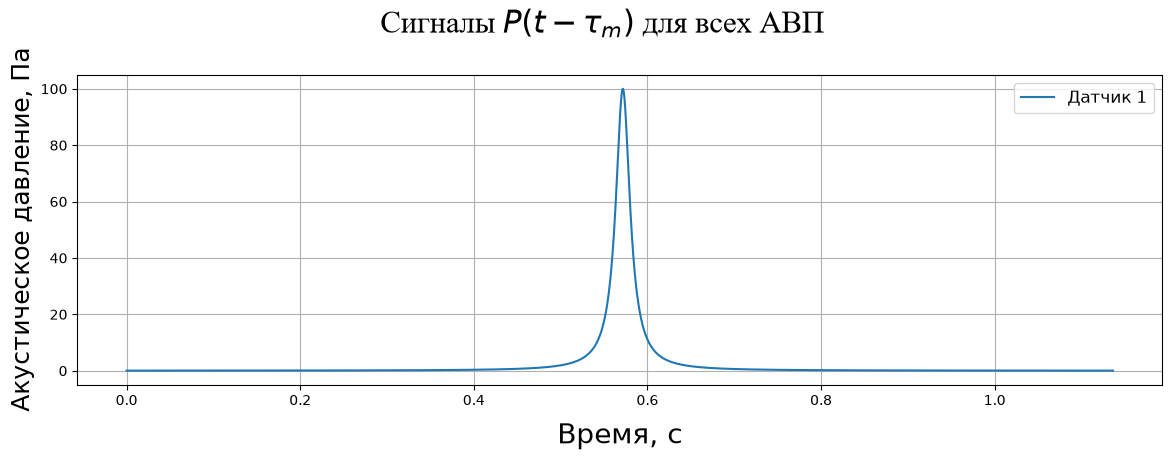

In [ ]:
tau_array = get_tau_array(config_parametrs)
params_vector_copy = config_parametrs.copy()

fig, ax = plt.subplots(1, 1, figsize=(14, 5))
fig.subplots_adjust(top=0.80, bottom=0.18)

# Сигнал на каждом датчике
for idx, tau in enumerate(tau_array):
    params_vector_copy["time_vector"] = config_parametrs["time_vector"] - tau
    signal = get_impulse_signal(params_vector_copy)

    ax.plot(
        config_parametrs["time_vector"], signal,
        label=f"Датчик {idx + 1}"
    )

# Названия осей и заголовок
ax.set_xlabel("Время, с", labelpad=10, fontsize=20)
ax.set_ylabel("Акустическое давление, Па", fontsize=18)
fig.suptitle(
    r"Сигналы $P(t-\tau_m)$ для всех АВП",
    y=0.90, va="center",
    fontfamily="Times New Roman", fontsize=22
)

ax.grid(True)
ax.legend(loc="upper right", fontsize=12)

plt.show()

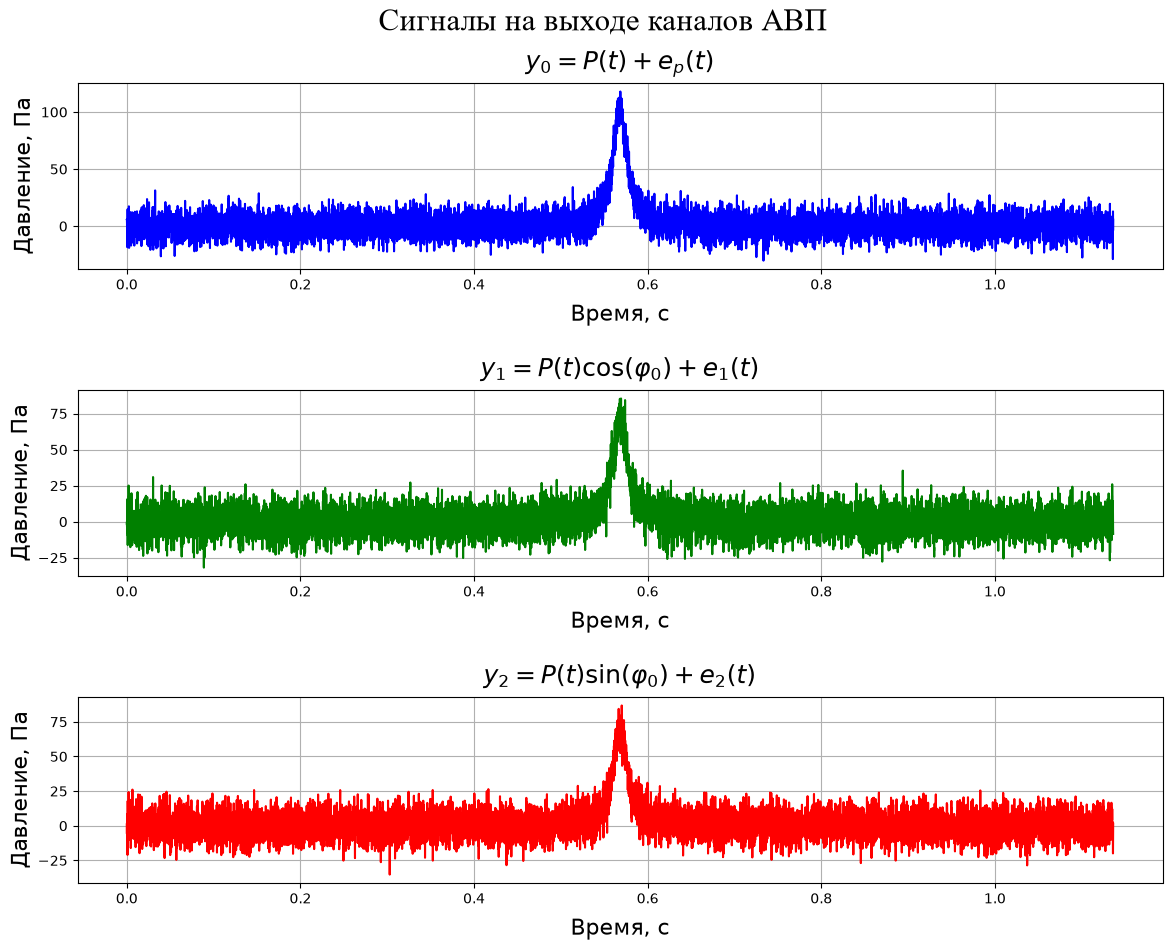

In [ ]:
cfg.init_rng()
title_main = r"Сигналы на выходе каналов АВП"
signals = get_avp_signals(pulse_signal_copy, config_parametrs, energy_pulse_value)

fig, axs = plt.subplots(3, 1, figsize=(14, 10))
fig.subplots_adjust(top=0.88, bottom=0.08, hspace=0.65)

fig.suptitle(
    title_main,
    y=0.94, va="center",
    fontfamily="Times New Roman", fontsize=22
)

colors = ("blue", "green", "red")
titles = (
    r"$y_0 = P(t) + e_p(t)$",
    r"$y_1 = P(t)\cos(\varphi_0) + e_1(t)$",
    r"$y_2 = P(t)\sin(\varphi_0) + e_2(t)$"
)

for ax, lambda_values, title, color in zip(axs, signals.values(), titles, colors):
    ax.plot(cfg.TIME_VECTOR, lambda_values, color=color)
    ax.set_xlabel("Время, с", labelpad=8, fontsize=16)
    ax.set_ylabel("Давление, Па", fontsize=16)
    ax.set_title(title, pad=10, fontsize=18)
    ax.grid(True)
    
plt.savefig(fname = f"images/notebook/{str(title_main)}", bbox_inches = 'tight', dpi = 300)
plt.show()

In [ ]:
channel_matrix = get_channel_matrix(config_parametrs, tau_array, get_impulse_signal)
W = get_covariation_matrix(channel_matrix, cfg.N)
dir_matrix = get_direction_matrix(cfg.PHI_VECTOR, cfg.M)
E_bar = get_barlet_values(W,dir_matrix)
E_cap = get_cap_values(W, dir_matrix)


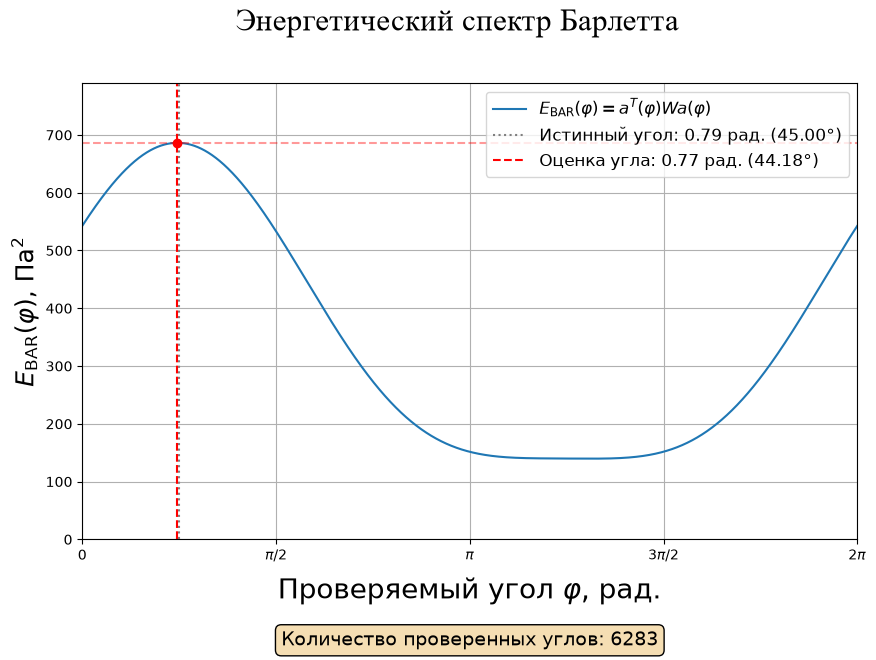

In [ ]:

title_main = "Энергетический спектр Барлетта"

sigma_noise = noise_level
phi_0 = cfg.TARGET_PHI
phi_vector = cfg.PHI_VECTOR
A = cfg.A

est_phi = get_est_phi(phi_vector, E_bar)
E_max = max(E_bar)

snr_ratio = np.inf if sigma_noise == 0 else A**2 / sigma_noise**2
snr_text = (
    "∞ (без шума)" if np.isinf(snr_ratio)
    else f"{snr_ratio:.2f} ({10 * np.log10(snr_ratio):.2f} дБ)"
)

fig, ax = plt.subplots(figsize=(10, 8))
fig.subplots_adjust(top=0.85, bottom=0.28)

# Функция Бартлетта и отметки углов
ax.plot(
    phi_vector, E_bar,
    label=r"$E_{\mathrm{BAR}}(\varphi)=a^T(\varphi)W a(\varphi)$"
)


ax.axvline(
    phi_0, color="gray", linestyle=":",
    label=f"Истинный угол: {phi_0:.2f} рад. ({np.degrees(phi_0):.2f}°)"
)
ax.axvline(
    est_phi, color="red", linestyle="--",
    label=f"Оценка угла: {est_phi:.2f} рад. ({np.degrees(est_phi):.2f}°)"
)

ax.scatter(est_phi, E_max, color="red", zorder=3)
ax.axhline(E_max, color="red", linestyle="--", alpha=0.4)

# Названия осей и заголовок
fig.suptitle(
    title_main,
    y=0.925, va="center",
    fontfamily="Times New Roman", fontsize=22
)

ax.set_xlabel(r"Проверяемый угол $\varphi$, рад.", labelpad=10, fontsize=20)
ax.set_ylabel(r"$E_{\mathrm{BAR}}(\varphi)$, Па$^2$", fontsize=18)

ax.set_xticks(
    [0, np.pi / 2, np.pi, 3 * np.pi / 2, 2 * np.pi],
    ["0", r"$\pi/2$", r"$\pi$", r"$3\pi/2$", r"$2\pi$"]
)

ax.set_xlim(0, 2 * np.pi)
ax.set_ylim(0, 1.15 * E_max)
ax.legend(loc="upper right", fontsize=12)
ax.grid(True)



# Количество углов в сетке поиска
info = f"Количество проверенных углов: {len(phi_vector)}"
ax.text(
    0.5, -0.20, info,
    transform=ax.transAxes,
    fontsize=14,
    ha="center", va="top",
    bbox=dict(boxstyle="round", facecolor="wheat", alpha=1),
    clip_on=False
)
plt.savefig(fname = f"images/notebook/{title_main}", bbox_inches = 'tight', dpi = 300)
plt.show()

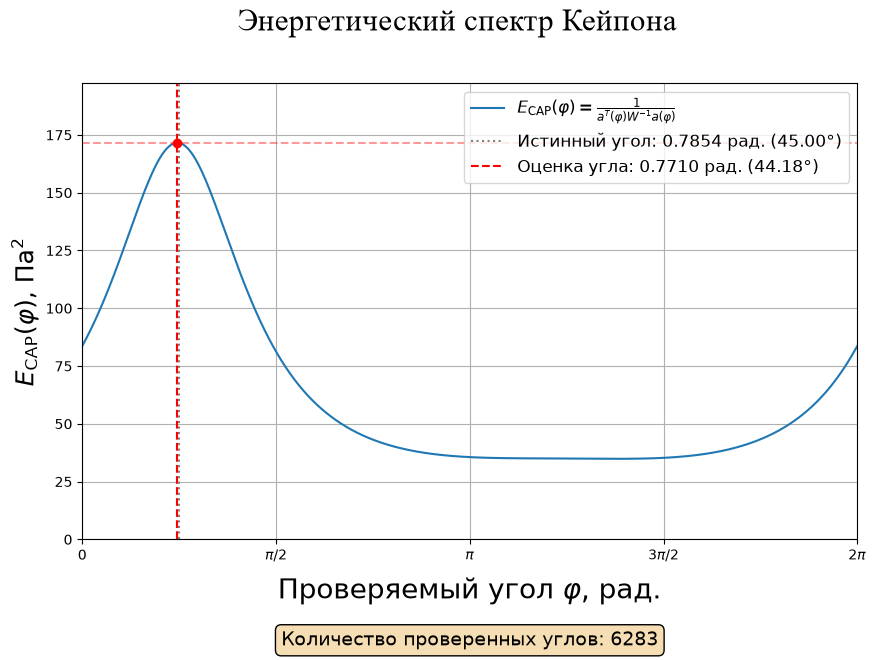

In [ ]:
title_main = "Энергетический спектр Кейпона"

sigma_noise = noise_level
phi_0 = cfg.TARGET_PHI
phi_vector = cfg.PHI_VECTOR
A = cfg.A

est_phi = get_est_phi(phi_vector, E_cap)
E_max = max(E_cap)

snr_ratio = np.inf if sigma_noise == 0 else A**2 / sigma_noise**2
snr_text = (
    "∞ (без шума)" if np.isinf(snr_ratio)
    else f"{snr_ratio:.2f} ({10 * np.log10(snr_ratio):.2f} дБ)"
)

fig, ax = plt.subplots(figsize=(10, 8))
fig.subplots_adjust(top=0.85, bottom=0.28)

# Функция Кейпона и отметки углов
ax.plot(
    phi_vector, E_cap,
    label=r"$E_{\mathrm{CAP}}(\varphi)=\frac{1}{a^T(\varphi)W^{-1}a(\varphi)}$"
)


ax.axvline(
    phi_0, color="gray", linestyle=":",
    label=f"Истинный угол: {phi_0:.4f} рад. ({np.degrees(phi_0):.2f}°)"
)
ax.axvline(
    est_phi, color="red", linestyle="--",
    label=f"Оценка угла: {est_phi:.4f} рад. ({np.degrees(est_phi):.2f}°)"
)

ax.scatter(est_phi, E_max, color="red", zorder=3)
ax.axhline(E_max, color="red", linestyle="--", alpha=0.4)

# Названия осей и заголовок
fig.suptitle(
    "Энергетический спектр Кейпона",
    y=0.925, va="center",
    fontfamily="Times New Roman", fontsize=22
)

ax.set_xlabel(r"Проверяемый угол $\varphi$, рад.", labelpad=10, fontsize=20)
ax.set_ylabel(r"$E_{\mathrm{CAP}}(\varphi)$, Па$^2$", fontsize=18)

ax.set_xticks(
    [0, np.pi / 2, np.pi, 3 * np.pi / 2, 2 * np.pi],
    ["0", r"$\pi/2$", r"$\pi$", r"$3\pi/2$", r"$2\pi$"]
)

ax.set_xlim(0, 2 * np.pi)
ax.set_ylim(0, 1.15 * E_max)
ax.legend(loc="upper right", fontsize=12)
ax.grid(True)



# Количество углов в сетке поиска
info = f"Количество проверенных углов: {len(phi_vector)}"
ax.text(
    0.5, -0.20, info,
    transform=ax.transAxes,
    fontsize=14,
    ha="center", va="top",
    bbox=dict(boxstyle="round", facecolor="wheat", alpha=1),
    clip_on=False
)
plt.savefig(fname = f"images/notebook/{title_main}", bbox_inches = 'tight', dpi = 300)
plt.show()

<>:18: SyntaxWarning: invalid escape sequence '\l'
<>:18: SyntaxWarning: invalid escape sequence '\l'
C:\Users\Admin\AppData\Local\Temp\ipykernel_11592\353055895.py:18: SyntaxWarning: invalid escape sequence '\l'
  ax.set_ylabel("$\lambda_{RMS}$, м", fontsize = 16)


Text(0, 0.5, '$\\beta_{pulse}$, сек.')

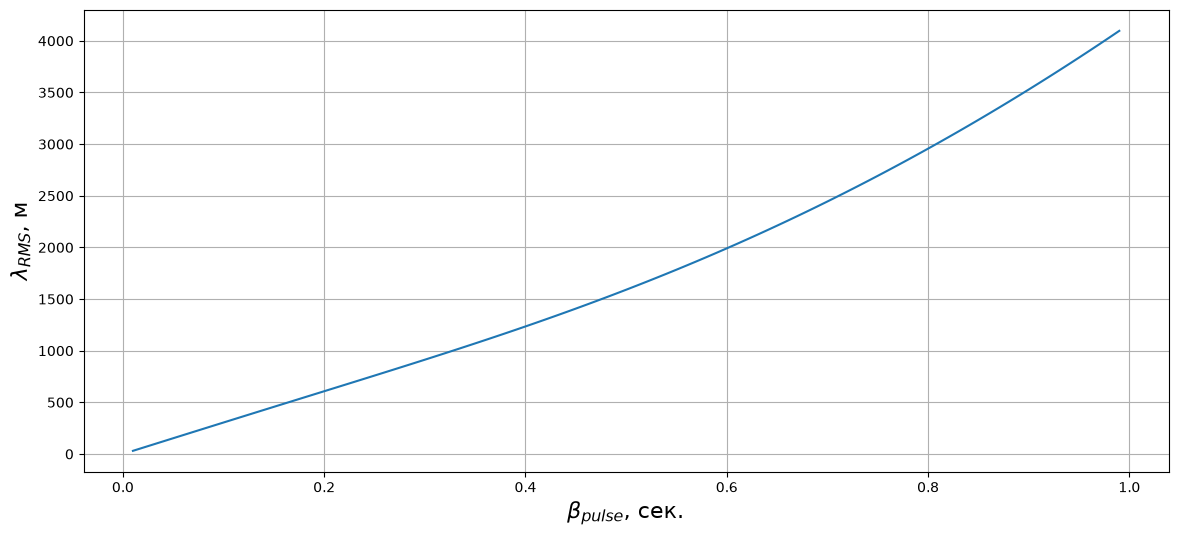

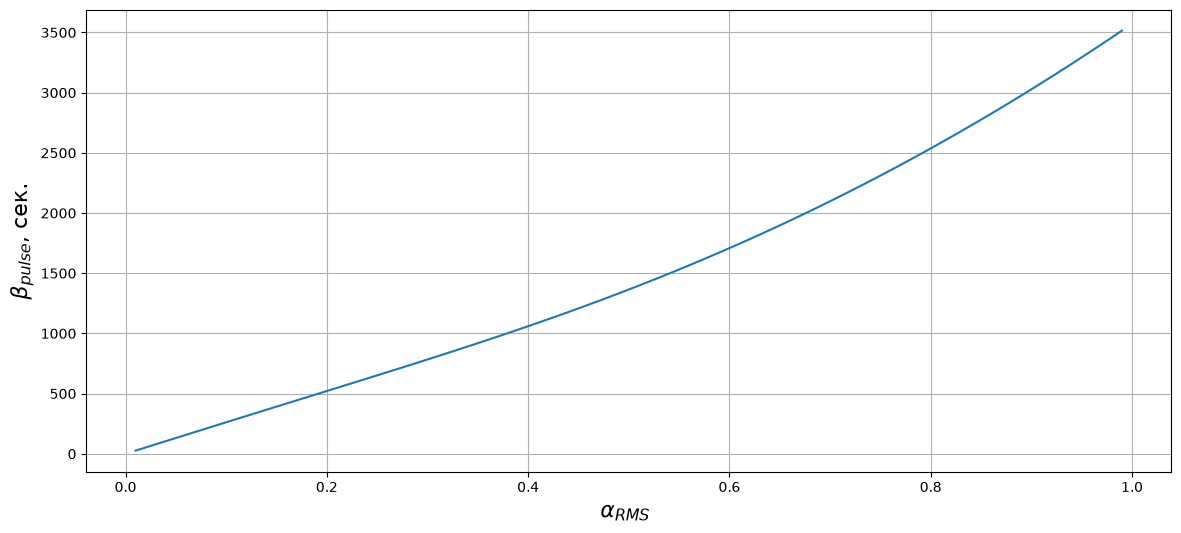

In [ ]:
new_config = config_parametrs.copy()
betta_values = []
lambda_values = []
alpha_values = []
for b in list(range(1,100)):
    new_config["duration_pulse"] = b/100
    pulse_signal_copy = get_impulse_signal(new_config)
    spectrum_signal_copy = calculate_freq_spectr(pulse_signal_copy, cfg.FS)
    rms_betta = calculate_f_rms(spectrum_signal_copy, config_parametrs)
    betta_values.append(b/100)
    lamda = cfg.SPEED_ON_SOUND / rms_betta
    lambda_values.append(lamda)
    alpha_values.append(lamda / 2 * cfg.R)

fig, ax = plt.subplots(1,1,figsize = (14,6))
ax.plot(betta_values,lambda_values)
ax.grid(True)
ax.set_ylabel("$\lambda_{RMS}$, м", fontsize = 16)
ax.set_xlabel(r"$\beta_{pulse}$, сек.", fontsize = 16)

fig, ax = plt.subplots(1,1,figsize = (14,6))
ax.plot(betta_values,alpha_values)
ax.grid(True)
ax.set_xlabel(r"$\alpha_{RMS}$ ", fontsize = 16)
ax.set_ylabel(r"$\beta_{pulse}$, сек.", fontsize = 16)